<a href="https://colab.research.google.com/github/basilhakim/NLP-classworks/blob/main/Word2VecExample2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from gensim.models import Word2Vec
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [ ]:
# Sample corpus of sentences
corpus = [
    "It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife.",
    "However little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed.",
    "My dear Mr. Bennet, said his wife to him one day, have you heard that Netherfield Park is let at last?",
    "Mr. Bingley was to dine with them that evening.",
    "Is he married or single?",
    "Oh! Single, my dear, to be sure! A single man of large fortune; four or five thousand a year."
]

In [ ]:
corpus

['It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife.',
 'However little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed.',
 'My dear Mr. Bennet, said his wife to him one day, have you heard that Netherfield Park is let at last?',
 'Mr. Bingley was to dine with them that evening.',
 'Is he married or single?',
 'Oh! Single, my dear, to be sure! A single man of large fortune; four or five thousand a year.']

In [ ]:
# Tokenize the sentences
sentences = [sentence.split() for sentence in corpus]

In [ ]:
sentences

[['It',
  'is',
  'a',
  'truth',
  'universally',
  'acknowledged,',
  'that',
  'a',
  'single',
  'man',
  'in',
  'possession',
  'of',
  'a',
  'good',
  'fortune,',
  'must',
  'be',
  'in',
  'want',
  'of',
  'a',
  'wife.'],
 ['However',
  'little',
  'known',
  'the',
  'feelings',
  'or',
  'views',
  'of',
  'such',
  'a',
  'man',
  'may',
  'be',
  'on',
  'his',
  'first',
  'entering',
  'a',
  'neighbourhood,',
  'this',
  'truth',
  'is',
  'so',
  'well',
  'fixed.'],
 ['My',
  'dear',
  'Mr.',
  'Bennet,',
  'said',
  'his',
  'wife',
  'to',
  'him',
  'one',
  'day,',
  'have',
  'you',
  'heard',
  'that',
  'Netherfield',
  'Park',
  'is',
  'let',
  'at',
  'last?'],
 ['Mr.', 'Bingley', 'was', 'to', 'dine', 'with', 'them', 'that', 'evening.'],
 ['Is', 'he', 'married', 'or', 'single?'],
 ['Oh!',
  'Single,',
  'my',
  'dear,',
  'to',
  'be',
  'sure!',
  'A',
  'single',
  'man',
  'of',
  'large',
  'fortune;',
  'four',
  'or',
  'five',
  'thousand',
  'a',


In [ ]:

# Train CBOW model
model = Word2Vec(sentences, vector_size=10, window=3, min_count=1, sg=1)

In [ ]:
# Function to calculate sentence embeddings by averaging word vectors
def sentence_embedding(sentence):
    words = sentence.split()
    vectors = [model.wv[word] for word in words if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

# Calculate embeddings for each sentence
embeddings = np.array([sentence_embedding(sentence) for sentence in corpus])

# Calculate cosine similarity between sentences
similarity_matrix = np.dot(embeddings, embeddings.T)
np.fill_diagonal(similarity_matrix, 0)  # Ignore self-similarity


In [ ]:
embeddings

array([[ 0.0094517 ,  0.01217839,  0.02091881,  0.00785404,  0.00396563,
        -0.01021887,  0.01640115,  0.02776268, -0.0309767 , -0.00876801],
       [-0.00521652, -0.00714957, -0.01129602, -0.00478335, -0.00042962,
         0.00449   ,  0.03767618,  0.02198583, -0.02228291,  0.00356907],
       [ 0.00561397,  0.00569847,  0.01720993, -0.0001548 , -0.00437322,
         0.00852573,  0.01940228, -0.01340912, -0.03066378, -0.02818706],
       [ 0.03776596, -0.00241426,  0.03033156,  0.01001621,  0.01202649,
        -0.01107869,  0.00108335, -0.0039499 , -0.01746448, -0.00092992],
       [ 0.01601537, -0.00292378, -0.00973087, -0.01680976,  0.01966462,
        -0.04353174, -0.0136843 ,  0.02681119,  0.00665561,  0.01203132],
       [-0.01824905, -0.01970177,  0.00552981, -0.01772546, -0.01435961,
        -0.01193735,  0.0175593 ,  0.01466473, -0.0184051 , -0.01205746]],
      dtype=float32)

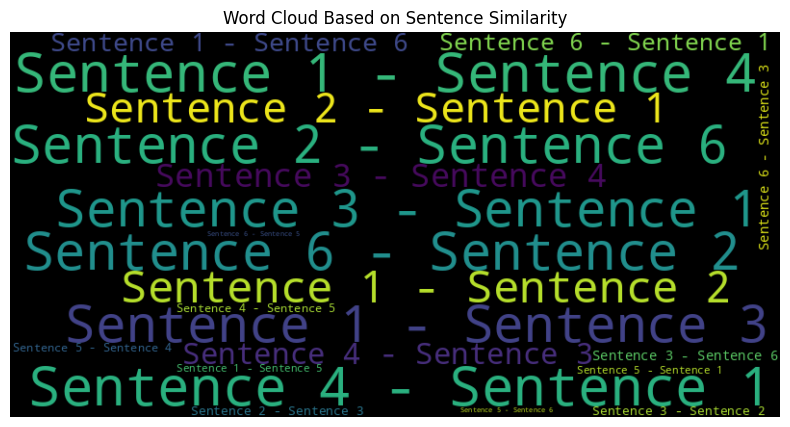

In [ ]:
# Create a dictionary for word cloud
word_freq = {}
for i in range(len(corpus)):
    for j in range(len(corpus)):
        if i != j:
            similarity_score = similarity_matrix[i][j]
            word_freq[f'Sentence {i+1} - Sentence {j+1}'] = similarity_score

# Generate and display the word cloud
wordcloud = WordCloud(width=800, height=400).generate_from_frequencies(word_freq)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide axes
plt.title('Word Cloud Based on Sentence Similarity')
plt.show()

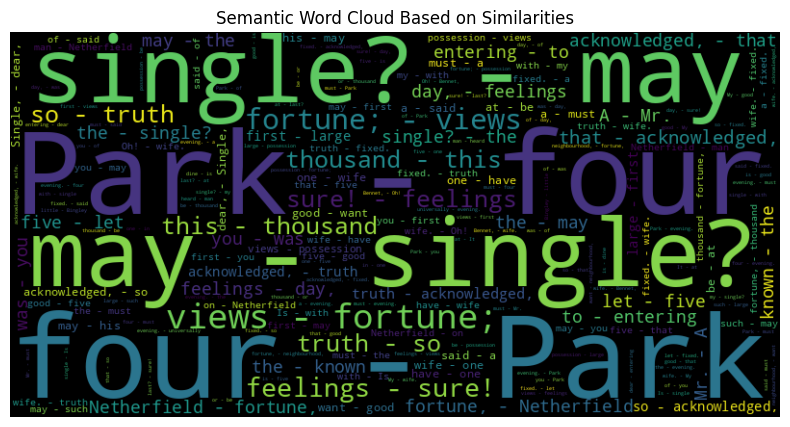

In [ ]:
# Create a dictionary to store similarity scores
similarity_dict = {}

# Calculate similarity for each pair of words in the vocabulary
for word1 in model.wv.key_to_index:
    for word2 in model.wv.key_to_index:
        if word1 != word2:
            similarity_score = model.wv.similarity(word1, word2)
            similarity_dict[f"{word1} - {word2}"] = similarity_score

# Filter out low similarity scores for better visualization
filtered_similarity = {k: v for k, v in similarity_dict.items() if v > 0.5}

# Generate and display the word cloud based on similarities
wordcloud = WordCloud(width=800, height=400).generate_from_frequencies(filtered_similarity)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide axes
plt.title('Semantic Word Cloud Based on Similarities')
plt.show()

Generated Sentence: simple example to illustrate how a simple but effective for
